# 06 — Model B: Cross-Period Next-Day AQI Forecasting

**Research question:** Can an AQI-only forecasting model trained on Indian city data from **2015–2020** forecast **tomorrow’s AQI** on recent observations from **2023–2025**?

This experiment is distinct from Aditri's same-day *pollutant-based* Model A and from the in-period recent-data models. We compare **persistence**, **Ridge**, **Random Forest** and **HistGradientBoosting**. All models use a **shared, pollutant-free feature schema**; no test-period targets are used for fitting. Later, a recent-data-trained reference model is evaluated on the **exact same held-out rows**.

**Important:** The supplied notebooks document paths but do not include the CSV data; this notebook is ready to run once those files are present in your repo. Run cells in order.

## 1. Imports, settings and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'Cleaned'
FIGURES = ROOT / 'reports' / 'figures' / 'model_b'
RESULTS = ROOT / 'reports' / 'results' / 'modelb'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

# File paths verified from the uploaded notebooks. Edit these if your repo differs.
OLD_CSV = DATA / 'city_day_clean.csv'
NEW_CSV = DATA / 'aqi_2023_2025_clean.csv'
# A valid alternative to NEW_CSV is a daily City/Date/AQI CSV.
RECENT_TRAIN_START = '2023-01-01'
RECENT_TEST_START = '2024-11-01'  # follows the in-period evaluation window
RECENT_TEST_END = '2025-04-30'
HISTORICAL_END = '2020-12-31'

print('Project root:', ROOT)
for p in [OLD_CSV, NEW_CSV]:
    print(('FOUND' if p.exists() else 'MISSING'), p)
if not (OLD_CSV.exists() and NEW_CSV.exists()):
    raise FileNotFoundError('Place both cleaned CSVs at the paths shown above, then rerun. Do not substitute pre-generated feature tables.')

Project root: d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India
FOUND d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\data\Cleaned\city_day_clean.csv
FOUND d:\IISER\7th sem\idc409(data science)\AQI_project_idc409\AQI-prediction-India\data\Cleaned\aqi_2023_2025_clean.csv


## 2. Load datasets

The older data comes from `data/Cleaned/city_day_clean.csv` (Aditri's `01_eda.ipynb`); the newer data from `data/Cleaned/aqi_2023_2025_clean.csv` (your `03_feature_engineering_2023_25.ipynb`). No pollutant variables are necessary for this **AQI-only** experiment.

In [2]:
old_raw = pd.read_csv(OLD_CSV, low_memory=False)
new_raw = pd.read_csv(NEW_CSV, low_memory=False)
print('Historical raw shape:', old_raw.shape)
print('Recent raw shape:', new_raw.shape)
print('Old columns:', list(old_raw.columns))
print('New columns:', list(new_raw.columns))

Historical raw shape: (24801, 23)
Recent raw shape: (235005, 7)
Old columns: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'Day', 'Weekday', 'Is_Weekend', 'Season', 'Is_Winter', 'Is_Diwali_Period']
New columns: ['Date', 'state', 'City', 'number_of_monitoring_stations', 'prominent_pollutants', 'AQI', 'AQI_Bucket']


## 3. Standardize City, Date and AQI; verify coverage and overlap

In [3]:
# Add only verified or explicitly reviewed spelling aliases, not fuzzy-matched guesses.
CITY_ALIASES = {
    'Gurgaon': 'Gurugram',
    'New Delhi': 'Delhi',
    'Bangalore': 'Bengaluru',
}

def normalize(raw, source):
    rename = {'area':'City', 'city':'City', 'date':'Date', 'aqi_value':'AQI', 'aqi':'AQI'}
    d = raw.rename(columns={k:v for k,v in rename.items() if k in raw and v not in raw}).copy()
    required = {'City','Date','AQI'}
    if not required.issubset(d.columns):
        raise ValueError(f'{source}: missing columns {required - set(d.columns)}')
    d = d[['City','Date','AQI']].copy()
    # Explicit format handling avoids mixing day/month order without inspection.
    dt_iso = pd.to_datetime(d['Date'], format='%Y-%m-%d', errors='coerce')
    dt_dmy = pd.to_datetime(d['Date'], format='%d-%m-%Y', errors='coerce')
    d['Date'] = dt_iso if dt_iso.notna().sum() >= dt_dmy.notna().sum() else dt_dmy
    d['Date'] = d['Date'].dt.normalize()
    d['City'] = d['City'].astype('string').str.strip().str.title().replace(CITY_ALIASES)
    d['AQI'] = pd.to_numeric(d['AQI'], errors='coerce')
    d = d.dropna(subset=['City','Date','AQI']).copy()
    d = d[d['AQI'].between(0, 500)]  # CPCB-index domain; review out-of-range exclusions
    duplicates = d.duplicated(['City','Date'], keep=False).sum()
    if duplicates:
        print(f'{source}: {duplicates} duplicate city-date rows; using median AQI per city-date')
    d = d.groupby(['City','Date'], as_index=False)['AQI'].median()
    d['source'] = source
    return d.sort_values(['City','Date']).reset_index(drop=True)

old = normalize(old_raw, 'historical_2015_2020')
new = normalize(new_raw, 'recent_2023_2025')
old = old[old['Date'] <= pd.Timestamp(HISTORICAL_END)].copy()
new = new[new['Date'] >= pd.Timestamp(RECENT_TRAIN_START)].copy()

for name,d in [('Historical',old),('Recent',new)]:
    print(name, 'rows:',len(d),'cities:',d.City.nunique(), 'dates:',d.Date.min(), 'to',d.Date.max())

common_cities = sorted(set(old.City) & set(new.City))
print('Overlapping cities:',len(common_cities))
print('Examples:',common_cities[:30])
if not common_cities:
    raise ValueError('No shared cities: inspect city spelling and revise CITY_ALIASES after validating mappings.')
old = old[old.City.isin(common_cities)].copy()
new = new[new.City.isin(common_cities)].copy()

Historical rows: 24258 cities: 26 dates: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Recent rows: 191718 cities: 290 dates: 2023-01-01 00:00:00 to 2025-04-30 00:00:00
Overlapping cities: 25
Examples: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


## 4. Shared, leakage-safe daily feature engineering

At each date **t**, `AQI` is the observed current-day AQI, and the target is **AQI(t+1)**. Previous-day lags and rolling statistics are built from a city-specific daily grid, so absent dates remain `NaN` rather than becoming the previous row. No future target is used as a feature. Date features are defined identically across datasets. Festival and pollutant features are **intentionally excluded** because comparable measurements are not guaranteed across both sources.

**Operational assumption:** today's finalized AQI is available when forecasting tomorrow. If you need an early-morning forecast, change that assumption and remove same-day AQI.

In [4]:
NUMERIC = ['AQI','AQI_lag1','AQI_lag2','AQI_lag3','AQI_lag7',
           'AQI_roll3','AQI_roll7','AQI_roll14','AQI_std7','AQI_change1',
           'month','weekday','is_weekend','is_winter']
CATEGORICAL = ['City','season']
FEATURES = NUMERIC + CATEGORICAL

def make_aqi_features(d):
    pieces = []
    for city, group in d.groupby('City', sort=True):
        group = group.sort_values('Date').set_index('Date')
        # Daily calendar prevents treating missing days as consecutive observations.
        daily = group[['AQI']].reindex(pd.date_range(group.index.min(),group.index.max(),freq='D'))
        daily.index.name = 'Date'
        daily['City'] = city
        for lag in (1,2,3,7):
            daily[f'AQI_lag{lag}'] = daily['AQI'].shift(lag)
        for w in (3,7,14):
            daily[f'AQI_roll{w}'] = daily['AQI'].shift(1).rolling(w,min_periods=max(2,int(w*0.7))).mean()
        daily['AQI_std7'] = daily['AQI'].shift(1).rolling(7,min_periods=5).std()
        daily['AQI_change1'] = daily['AQI'] - daily['AQI_lag1']
        daily['target_AQI_next'] = daily['AQI'].shift(-1)
        daily['target_date'] = daily.index + pd.Timedelta(days=1)
        daily['month'] = daily.index.month
        daily['weekday'] = daily.index.dayofweek
        daily['is_weekend'] = (daily['weekday'] >= 5).astype(int)
        daily['is_winter'] = daily['month'].isin([11,12,1,2]).astype(int)
        daily['season'] = np.select(
            [daily['month'].isin([12,1,2]), daily['month'].isin([3,4,5]),
             daily['month'].isin([6,7,8,9])],
            ['Winter','Summer','Monsoon'], default='Post-Monsoon')
        pieces.append(daily.reset_index())
    result = pd.concat(pieces,ignore_index=True)
    required = NUMERIC + ['target_AQI_next']
    result = result.dropna(subset=required).copy()
    return result.sort_values(['Date','City']).reset_index(drop=True)

historical_features = make_aqi_features(old)
recent_features = make_aqi_features(new)
print('Historical usable features:',len(historical_features))
print('Recent usable features:',len(recent_features))
display(historical_features[['City','Date','AQI','AQI_lag1','AQI_roll7','target_AQI_next']].head())

# Spot-check temporal alignment on sampled rows from BOTH datasets.
for label,source,features in [('historical',old,historical_features),('recent',new,recent_features)]:
    sampled = features.sample(min(200,len(features)),random_state=SEED)
    look = source.set_index(['City','Date'])['AQI']
    for r in sampled.itertuples(index=False):
        assert np.isclose(r.target_AQI_next,look.loc[(r.City,r.Date+pd.Timedelta(days=1))])
        assert np.isclose(r.AQI_lag1,look.loc[(r.City,r.Date-pd.Timedelta(days=1))])
    print(label,': temporal spot-check passed',len(sampled),'rows')

Historical usable features: 20793
Recent usable features: 16590


,City,Date,AQI,AQI_lag1,AQI_roll7,target_AQI_next
0,Delhi,2015-01-10,376.0,375.0,316.571429,379.0
1,Delhi,2015-01-11,379.0,376.0,349.857143,375.0
2,Delhi,2015-01-12,375.0,379.0,358.428571,366.0
3,Delhi,2015-01-13,366.0,375.0,365.571429,353.0
4,Delhi,2015-01-14,353.0,366.0,372.428571,340.0


historical : temporal spot-check passed 200 rows
recent : temporal spot-check passed 200 rows


## 5. Define a strict cross-period test and a fair recent-data comparator

**Model B train**: historical samples with target dates no later than 2020-12-31. **Test**: newer samples whose *target date* is 2024-11-01 through 2025-04-30. **Recent-trained reference**: newer samples whose target dates are before 2024-11-01. This is a different training distribution but is scored on the **same test rows**.

Only cities appearing in the historical, recent-training and test partitions are retained. Reuse the exact target-date window across all methods.

In [5]:
test_start = pd.Timestamp(RECENT_TEST_START)
test_end = pd.Timestamp(RECENT_TEST_END)
historical_train = historical_features[historical_features['target_date'] <= pd.Timestamp(HISTORICAL_END)].copy()
recent_train = recent_features[recent_features['target_date'] < test_start].copy()
test = recent_features[recent_features['target_date'].between(test_start,test_end)].copy()
valid_cities = set(historical_train.City) & set(recent_train.City) & set(test.City)
historical_train = historical_train[historical_train.City.isin(valid_cities)].copy()
recent_train = recent_train[recent_train.City.isin(valid_cities)].copy()
test = test[test.City.isin(valid_cities)].copy()
if min(len(historical_train),len(recent_train),len(test)) == 0:
    raise ValueError('One split is empty. Inspect dataset date coverage, CITY_ALIASES and test window.')
assert historical_train['target_date'].max() < recent_train['target_date'].min()
assert recent_train['target_date'].max() < test['target_date'].min()
assert not test.duplicated(['City','Date']).any()
for label,frame in [('Historical train',historical_train),('Recent train',recent_train),('Common test',test)]:
    print(f'{label}: {len(frame):,} rows; {frame.City.nunique()} cities; target dates',
          frame.target_date.min().date(),'to',frame.target_date.max().date())
print('Common cities:',sorted(valid_cities))

Historical train: 20,112 rows; 23 cities; target dates 2015-01-11 to 2020-07-01
Recent train: 12,753 rows; 23 cities; target dates 2023-01-11 to 2024-10-31
Common test: 3,604 rows; 23 cities; target dates 2024-11-01 to 2025-04-30
Common cities: ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


## 6. Train persistence, Ridge, Random Forest and HistGradientBoosting

In [6]:
def make_encoder():
    # Handle older versions of scikit-learn that use sparse= rather than sparse_output=.
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)

def make_preprocessor(scale=False):
    numeric_steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale: numeric_steps.append(('scaler',StandardScaler()))
    return ColumnTransformer([
        ('num',Pipeline(numeric_steps),NUMERIC),
        ('cat',make_encoder(),CATEGORICAL)
    ],remainder='drop')

def make_models():
    return {
        'Ridge Regression':Pipeline([('pre',make_preprocessor(True)),('model',Ridge(alpha=1.0))]),
        'Random Forest':Pipeline([('pre',make_preprocessor()),('model',RandomForestRegressor(
            n_estimators=150,min_samples_leaf=5,max_features=0.8,n_jobs=-1,random_state=SEED))]),
        'Hist Gradient Boosting':Pipeline([('pre',make_preprocessor()),('model',HistGradientBoostingRegressor(
            max_iter=180,random_state=SEED))]),
    }

def evaluate(y,pred,name,training_period):
    return {'Training':training_period,'Model':name,
            'MAE':mean_absolute_error(y,pred),
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'R2':r2_score(y,pred)}

actual = test['target_AQI_next'].to_numpy()
predictions = pd.DataFrame({'City':test.City.to_numpy(), 'Date':test.Date.to_numpy(),
                            'target_date':test.target_date.to_numpy(),'actual':actual})
results = []
predictions['Persistence'] = test['AQI'].to_numpy()
results.append(evaluate(actual,predictions['Persistence'],'Persistence (tomorrow = today)','No fitting'))

historical_fitted = {}
for name,model in make_models().items():
    model.fit(historical_train[FEATURES], historical_train['target_AQI_next'])
    p = model.predict(test[FEATURES])
    predictions['Historical - '+name] = p
    results.append(evaluate(actual,p,name,'Historical 2015–2020'))
    historical_fitted[name] = model
    print('Completed historical:',name)

display(pd.DataFrame(results).round(3))

Completed historical: Ridge Regression
Completed historical: Random Forest
Completed historical: Hist Gradient Boosting


,Training,Model,MAE,RMSE,R2
0,No fitting,Persistence (tomorrow = today),24.270,35.826,0.769
1,Historical 2015–2020,Ridge Regression,23.336,33.477,0.798
2,Historical 2015–2020,Random Forest,23.458,33.569,0.797
3,Historical 2015–2020,Hist Gradient Boosting,23.210,33.363,0.800


## 7. Regression evaluation and exported predictions

,Training,Model,MAE,RMSE,R2
0,Historical 2015–2020,Hist Gradient Boosting,23.210,33.363,0.800
1,Historical 2015–2020,Ridge Regression,23.336,33.477,0.798
2,Historical 2015–2020,Random Forest,23.458,33.569,0.797
3,No fitting,Persistence (tomorrow = today),24.270,35.826,0.769


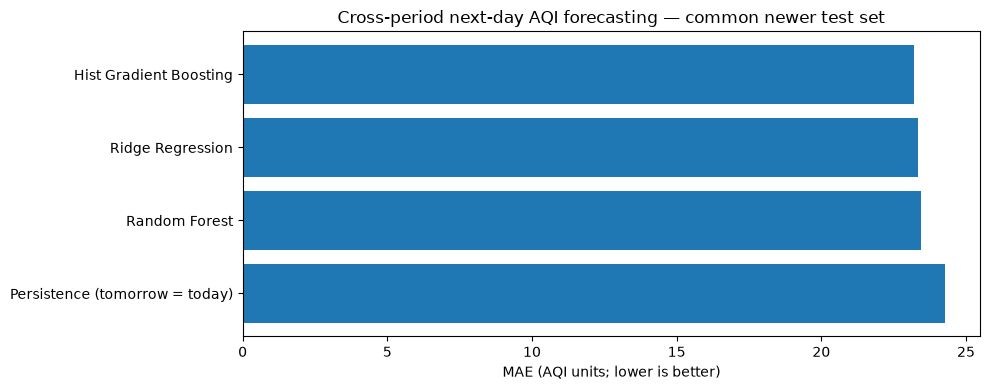

In [7]:
cross_period_results = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
display(cross_period_results.round(3))
cross_period_results.to_csv(RESULTS/'historical_model_results.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(cross_period_results['Model'],cross_period_results['MAE'])
ax.invert_yaxis();ax.set_xlabel('MAE (AQI units; lower is better)')
ax.set_title('Cross-period next-day AQI forecasting — common newer test set')
fig.tight_layout();fig.savefig(FIGURES/'cross_period_mae.png',dpi=160);plt.show()

## 8. Visualize actual vs predicted AQI and city-wise errors

Best historical model: Historical - Hist Gradient Boosting


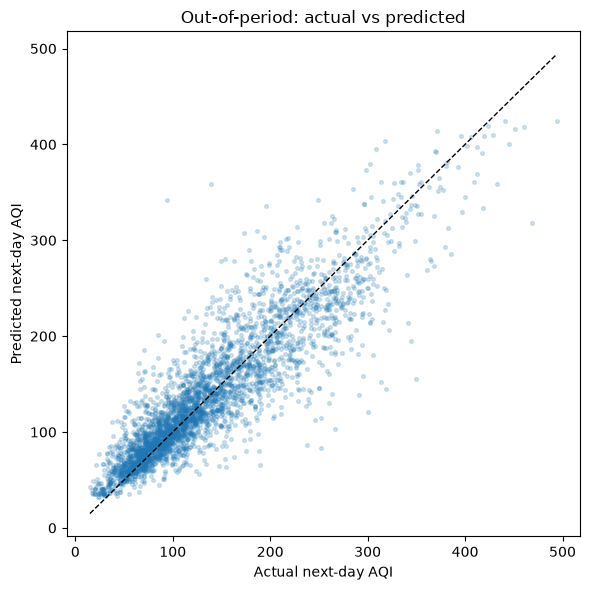

,City,n,Historical_MAE,Persistence_MAE
13,Hyderabad,175,7.58,7.81
4,Bengaluru,175,10.34,10.46
1,Aizawl,145,12.96,11.62
17,Mumbai,175,13.59,14.31
8,Chennai,175,15.11,15.21
2,Amaravati,148,18.96,19.88
9,Coimbatore,169,19.04,20.03
6,Brajrajnagar,113,19.20,19.49
15,Kolkata,175,21.10,21.81
5,Bhopal,175,21.99,24.53


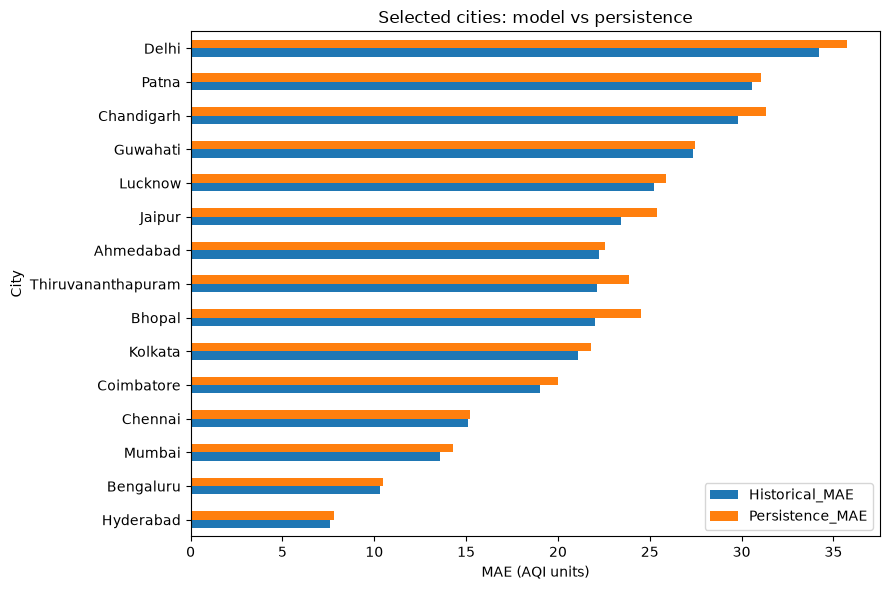

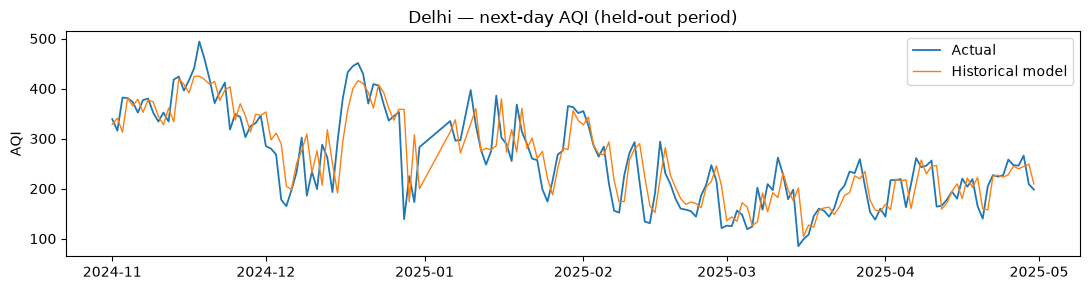

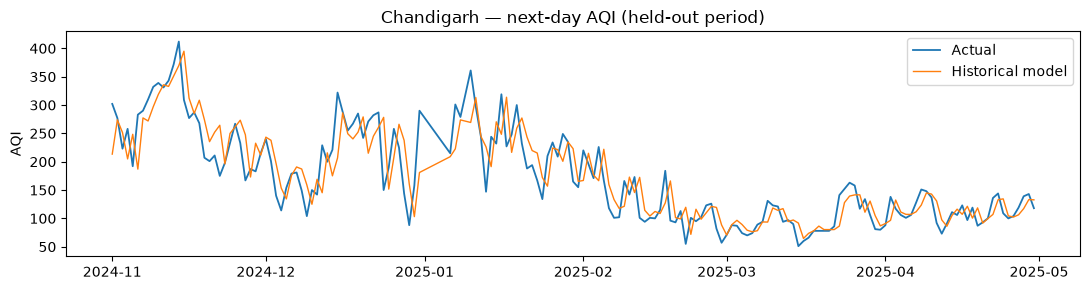

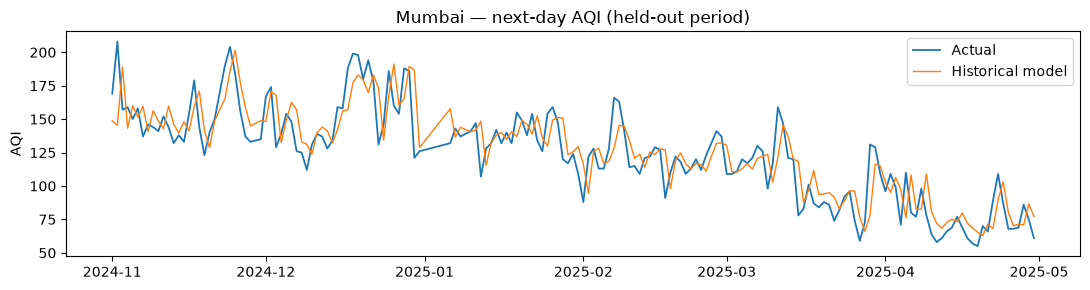

In [8]:
best_historical_name = min([x for x in predictions.columns if x.startswith('Historical - ')],
                           key=lambda x:mean_absolute_error(actual,predictions[x]))
print('Best historical model:',best_historical_name)
fig,ax=plt.subplots(figsize=(6,6))
ax.scatter(actual,predictions[best_historical_name],s=7,alpha=.2)
limits=(min(actual.min(),predictions[best_historical_name].min()),
        max(actual.max(),predictions[best_historical_name].max()))
ax.plot(limits,limits,'k--',lw=1);ax.set(xlabel='Actual next-day AQI',ylabel='Predicted next-day AQI',
                                       title='Out-of-period: actual vs predicted')
fig.tight_layout();fig.savefig(FIGURES/'actual_vs_predicted.png',dpi=160);plt.show()

city_rows=[]
for city,g in predictions.groupby('City'):
    if len(g)<10: continue
    city_rows.append({'City':city,'n':len(g),'Historical_MAE':mean_absolute_error(g.actual,g[best_historical_name]),
                      'Persistence_MAE':mean_absolute_error(g.actual,g['Persistence'])})
city_scores=pd.DataFrame(city_rows).sort_values('Historical_MAE')
display(city_scores.head(15).round(2))
city_scores.to_csv(RESULTS/'city_wise_errors.csv',index=False)
if len(city_scores):
    show=city_scores.sort_values('n',ascending=False).head(15).sort_values('Historical_MAE')
    ax=show.set_index('City')[['Historical_MAE','Persistence_MAE']].plot.barh(figsize=(9,6))
    ax.set_xlabel('MAE (AQI units)');ax.set_title('Selected cities: model vs persistence')
    plt.tight_layout();plt.savefig(FIGURES/'city_wise_mae.png',dpi=160);plt.show()

for city in ['Delhi','Chandigarh','Mumbai']:
    sample=predictions[predictions.City==city].sort_values('target_date')
    if sample.empty:
        print(city,'not present in common test cities');continue
    fig,ax=plt.subplots(figsize=(11,3))
    ax.plot(sample.target_date,sample.actual,label='Actual',lw=1.3)
    ax.plot(sample.target_date,sample[best_historical_name],label='Historical model',lw=1)
    ax.set(title=f'{city} — next-day AQI (held-out period)',ylabel='AQI');ax.legend()
    fig.tight_layout();fig.savefig(FIGURES/f'forecast_{city.lower()}.png',dpi=160);plt.show()

## 9. Fair comparison: recent-trained models on the identical held-out rows

To assess **distribution shift**, fit the *same* feature definitions and model configurations on the **recent training window only**, then score on the already-defined test set. Do not copy scores from `04_modelling_2023_25.ipynb`: that notebook may use extra pollutant/station features and a different subset of cities. We compare training periods only after aligning the test observations and input features.